In [1]:
#!/usr/bin/env python3
import sys
from obspy.taup import TauPyModel

def get_PKIKP_travel_time(distance_deg, depth_km, model_name="iasp91"):
    """
    Calculates the travel time for the PKIKP phase using ObsPy TauPyModel.
    """
    try:
        # Load the 1D Earth velocity model (iasp91, ak135, prem, etc.)
        model = TauPyModel(model=model_name)
        
        # Calculate all arrivals for the specified phase list
        arrivals = model.get_travel_times(
            source_depth_in_km=depth_km,
            distance_in_degree=distance_deg,
            phase_list=["PKIKP"]
        )
        
        # If a valid path exists through the inner core, return the first arrival
        if arrivals:
            pkikp_arrival = arrivals[0]
            #print(f"--- PKIKP Phase Arrival Information ({model_name.upper()}) ---")
            ##print(f"Distance:     {distance_deg}°")
            #print(f"Source Depth: {depth_km} km")
            #print(f"Travel Time:  {pkikp_arrival.time:.2f} seconds")
            #print(f"Ray Parameter: {pkikp_arrival.ray_param_sec_degree:.3f} s/deg")
            return pkikp_arrival.ray_param_sec_degree, pkikp_arrival.time
        else:
            return float('nan'), float('nan') 

    except Exception as e:
        print(f"An error occurred: {e}")
        return None

def get_PKJKP_travel_time(distance_deg, depth_km, model_name="iasp91"):
    """
    Calculates the travel time for the PKJKP phase using ObsPy TauPyModel.
    """
    try:
        # Load the 1D Earth velocity model (iasp91, ak135, prem, etc.)
        model = TauPyModel(model=model_name)
        
        # Calculate all arrivals for the specified phase list
        arrivals = model.get_travel_times(
            source_depth_in_km=depth_km,
            distance_in_degree=distance_deg,
            phase_list=["PKJKP"]
        )
        
        # If a valid path exists through the inner core, return the first arrival
        if arrivals:
            pkjkp_arrival = arrivals[0]
            #print(f"--- PKJKP Phase Arrival Information ({model_name.upper()}) ---")
            #print(f"Distance:     {distance_deg}°")
            #print(f"Source Depth: {depth_km} km")
            #print(f"Travel Time:  {pkjkp_arrival.time:.2f} seconds")
            #print(f"Ray Parameter: {pkjkp_arrival.ray_param_sec_degree:.3f} s/deg")
            return pkjkp_arrival.ray_param_sec_degree, pkjkp_arrival.time
        else:
            return float('nan'), float('nan') 

    except Exception as e:
        print(f"An error occurred: {e}")
        return None

In [2]:
if __name__ == "__main__":
    # Example usage parsing command line arguments
    if len(sys.argv) < 3:
        print("Usage: python get_pkikp_time.py <distance_degrees> <depth_km> [model_name]")
        print("Example: python get_pkikp_time.py 150 45")
        sys.exit(1)
        
    dist = 120
    dep = 0
    mod = sys.argv[3] if len(sys.argv) == 4 else "iasp91"
    
    get_PKIKP_travel_time(dist, dep, mod)
    get_PKJKP_travel_time(dist, dep, mod)

In [3]:
import matplotlib.pyplot as plt
import numpy as np
distance = np.linspace(0,180,181)

In [4]:
tt_I = np.ones(len(distance)) * np.nan
tt_J = np.ones(len(distance)) * np.nan
for i in range(len(distance)):
    tt_I[i] = get_PKIKP_travel_time(distance[i],dep,mod)[1]
    tt_J[i] = get_PKJKP_travel_time(distance[i],dep,mod)[1]

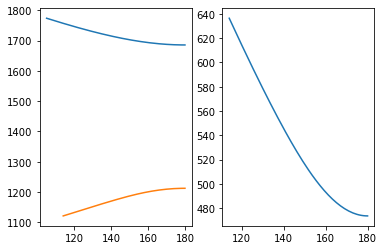

In [12]:
plt.subplot(1,2,1)
plt.plot(distance,tt_J)
plt.plot(distance,tt_I)

#new distance
distance_n = np.linspace(90,180,901)
plt.subplot(1,2,2)
plt.plot(distance_n, np.interp(distance_n, distance, tt_J)-np.interp(distance_n, distance, tt_I))
plt.show()
np.savetxt('I-J_phase_time.txt', np.column_stack((distance_n, np.interp(distance_n, distance, tt_J)-np.interp(distance_n, distance, tt_I))), header='dist    time', fmt='%.6f')